C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Epoch 1/10


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


163/163 ━━━━━━━━━━━━━━━━━━━━ 8247s 51s/step - accuracy: 0.8332 - loss: 0.7113 - val_accuracy: 0.8125 - val_loss: 0.4337
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 1638s 10s/step - accuracy: 0.9427 - loss: 0.1477 - val_accuracy: 0.7500 - val_loss: 0.4820
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 1434s 9s/step - accuracy: 0.9579 - loss: 0.1274 - val_accuracy: 0.7500 - val_loss: 0.4750
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 1424s 9s/step - accuracy: 0.9562 - loss: 0.1220 - val_accuracy: 0.8750 - val_loss: 0.2316
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 1607s 10s/step - accuracy: 0.9575 - loss: 0.1116 - val_accuracy: 0.6875 - val_loss: 0.8101
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 1617s 10s/step - accuracy: 0.9582 - loss: 0.1117 - val_accuracy: 0.7500 - val_loss: 0.3921
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 1749s 11s/step - accuracy: 0.9631 - loss: 0.1029 - val_accuracy: 0.7500 - val_loss: 0.3604
Epoch 8/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 1749s 11s/step - accuracy: 0.9612 - loss: 0.0969 - val_a

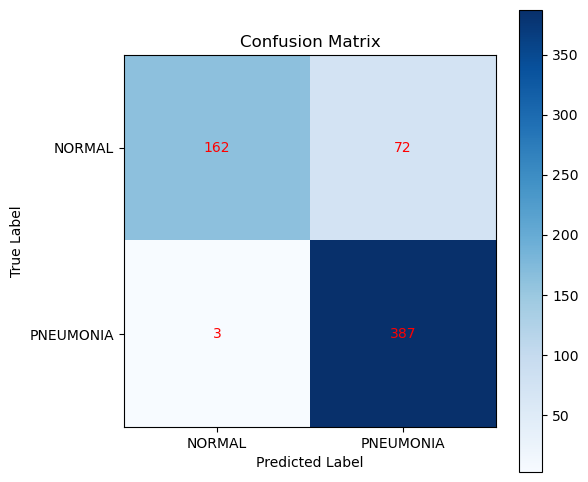

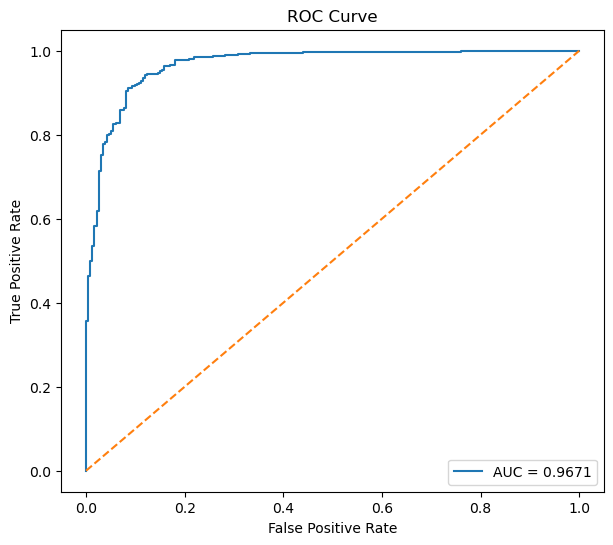


ROC-AUC Score: 0.9671378479070787


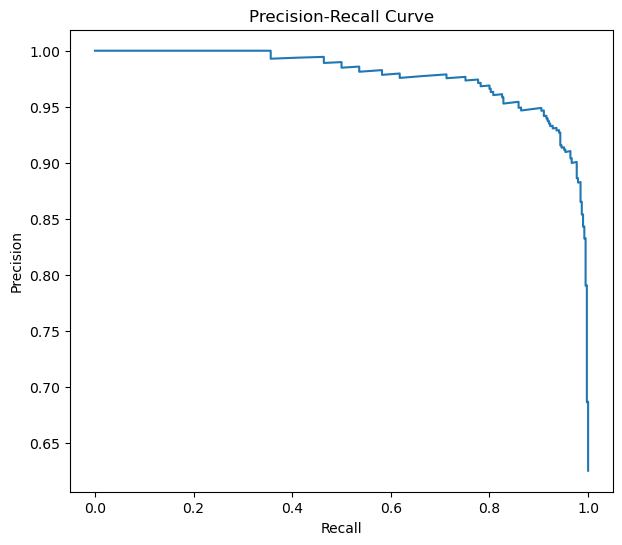

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)

# =========================
# Dataset Path
# =========================

train_path = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest x ray\train"
val_path   = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest x ray\val"
test_path  = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest x ray\test"

# =========================
# Image Parameters
# =========================

IMG_SIZE = 224
BATCH_SIZE = 32

# =========================
# Data Augmentation
# =========================

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.1,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(rescale=1./255)

# =========================
# Load Dataset
# =========================

train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

val_data = test_datagen.flow_from_directory(
    val_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

# =========================
# Load VGG16 Model
# =========================

base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
for layer in base_model.layers:
    layer.trainable = False

# =========================
# Build Model
# =========================

model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# =========================
# Compile Model
# =========================

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================
# Train Model
# =========================

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

# =========================
# Evaluate Model
# =========================

test_loss, test_accuracy = model.evaluate(test_data)

print("\nTest Accuracy:", test_accuracy)

# =========================
# Predictions
# =========================

y_prob = model.predict(test_data)
y_pred = (y_prob > 0.5).astype(int)

y_true = test_data.classes

# =========================
# Classification Report
# =========================

print("\nClassification Report:\n")

target_names = ['NORMAL', 'PNEUMONIA']

print(classification_report(
    y_true,
    y_pred,
    target_names=target_names
))

# =========================
# Confusion Matrix
# =========================

cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:\n")
print(cm)

# Plot Confusion Matrix
plt.figure(figsize=(6,6))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.colorbar()

classes = ['NORMAL', 'PNEUMONIA']
tick_marks = np.arange(len(classes))

plt.xticks(tick_marks, classes)
plt.yticks(tick_marks, classes)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, cm[i, j],
                 ha='center',
                 va='center',
                 color='red')

plt.show()
# 16. SENSITIVITY & SPECIFICITY
# =========================
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))

# =========================
# 17. INFERENCE TIME
# =========================
start = time.time()
_ = model.predict(test_gen)
end = time.time()

total_time = end - start
avg_time = total_time / len(test_df)

print("Total Inference Time:", round(total_time, 4), "sec")
print("Time per Image:", round(avg_time, 6), "sec")


# =========================
# ROC Curve
# =========================

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, label='AUC = %0.4f' % roc_auc)
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')

plt.show()

print("\nROC-AUC Score:", roc_auc)

# =========================
# Precision-Recall Curve
# =========================

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'PR Curve (AUC = {pr_auc:.2f})', color='darkorange', lw=2)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve (Class {target_class})')
plt.legend(loc='lower left')
plt.grid(True)
plt.tight_layout()
plt.show()
# Step 11: Training and Validation Accuracy/Loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()




In [1]:
import os
import shutil
import random

# ==========================================
# Original Dataset Path
# ==========================================

base_path = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest x ray"

train_path = os.path.join(base_path, "train")
val_path   = os.path.join(base_path, "val")
test_path  = os.path.join(base_path, "test")

# ==========================================
# New Dataset Path
# ==========================================

new_base_path = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new"

new_train = os.path.join(new_base_path, "train")
new_val   = os.path.join(new_base_path, "val")
new_test  = os.path.join(new_base_path, "test")

classes = ["NORMAL", "PNEUMONIA"]

# ==========================================
# Create New Folders
# ==========================================

for dataset in [new_train, new_val, new_test]:
    for cls in classes:
        os.makedirs(os.path.join(dataset, cls), exist_ok=True)

# ==========================================
# Collect All Images
# ==========================================

all_images = {}

for cls in classes:

    images = []

    # Read train images
    train_cls = os.path.join(train_path, cls)
    images += [os.path.join(train_cls, img) for img in os.listdir(train_cls)]

    # Read val images
    val_cls = os.path.join(val_path, cls)
    images += [os.path.join(val_cls, img) for img in os.listdir(val_cls)]

    # Read test images
    test_cls = os.path.join(test_path, cls)
    images += [os.path.join(test_cls, img) for img in os.listdir(test_cls)]

    random.shuffle(images)

    all_images[cls] = images

# ==========================================
# Split Dataset
# ==========================================

for cls in classes:

    images = all_images[cls]

    total = len(images)

    train_split = int(total * 0.70)
    val_split   = int(total * 0.15)

    train_imgs = images[:train_split]
    val_imgs   = images[train_split:train_split + val_split]
    test_imgs  = images[train_split + val_split:]

    # Copy Train Images
    for img in train_imgs:
        shutil.copy(img, os.path.join(new_train, cls))

    # Copy Validation Images
    for img in val_imgs:
        shutil.copy(img, os.path.join(new_val, cls))

    # Copy Test Images
    for img in test_imgs:
        shutil.copy(img, os.path.join(new_test, cls))

# ==========================================
# Done
# ==========================================

print("Dataset Successfully Reorganized!")

# ==========================================
# Show Dataset Statistics
# ==========================================

for dataset_name, dataset_path in zip(
    ["TRAIN", "VALIDATION", "TEST"],
    [new_train, new_val, new_test]
):

    print(f"\n{dataset_name}")

    total_images = 0

    for cls in classes:

        cls_path = os.path.join(dataset_path, cls)

        num_images = len(os.listdir(cls_path))

        total_images += num_images

        print(f"{cls}: {num_images}")

    print(f"Total Images: {total_images}")

Dataset Successfully Reorganized!

TRAIN
NORMAL: 1108
PNEUMONIA: 2991
Total Images: 4099

VALIDATION
NORMAL: 237
PNEUMONIA: 640
Total Images: 877

TEST
NORMAL: 238
PNEUMONIA: 642
Total Images: 880


In [4]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# =========================
# Dataset Path
# =========================

train_path = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\train"
val_path   = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\val"
test_path  = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\test"

# =========================
# Parameters
# =========================

IMG_SIZE = 224
BATCH_SIZE = 32

# =========================
# Data Generator
# =========================

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.1,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(rescale=1./255)

# =========================
# Load Dataset
# =========================

train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

val_data = test_datagen.flow_from_directory(
    val_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Found 4099 images belonging to 2 classes.
Found 877 images belonging to 2 classes.
Found 880 images belonging to 2 classes.


In [5]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_data.classes),
    y=train_data.classes
)

class_weights = dict(enumerate(class_weights))

print(class_weights)

{0: 1.8497292418772564, 1: 0.6852223336676697}


Found 4099 images belonging to 2 classes.
Found 880 images belonging to 2 classes.
Found 880 images belonging to 2 classes.

Class Weights:
{0: 1.8497292418772564, 1: 0.6852223336676697}
Epoch 1/10


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


129/129 ━━━━━━━━━━━━━━━━━━━━ 1695s 13s/step - accuracy: 0.7912 - loss: 0.7111 - val_accuracy: 0.8659 - val_loss: 0.2977
Epoch 2/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 1675s 13s/step - accuracy: 0.9237 - loss: 0.1989 - val_accuracy: 0.9500 - val_loss: 0.1619
Epoch 3/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 1616s 12s/step - accuracy: 0.9138 - loss: 0.2113 - val_accuracy: 0.9648 - val_loss: 0.1086
Epoch 4/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 1701s 13s/step - accuracy: 0.9331 - loss: 0.1787 - val_accuracy: 0.9352 - val_loss: 0.1705
Epoch 5/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 1443s 11s/step - accuracy: 0.9272 - loss: 0.1825 - val_accuracy: 0.8716 - val_loss: 0.2828
Epoch 6/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 1671s 13s/step - accuracy: 0.9323 - loss: 0.1698 - val_accuracy: 0.9091 - val_loss: 0.2244
Epoch 7/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 1715s 13s/step - accuracy: 0.9267 - loss: 0.1814 - val_accuracy: 0.9432 - val_loss: 0.1608
Epoch 8/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 1633s 13s/step - accuracy: 0.9468 - loss: 0.1429 - val

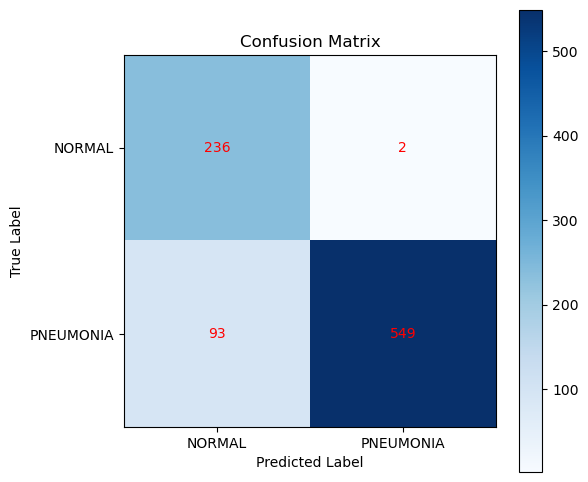

Sensitivity: 0.8551
Specificity: 0.9916


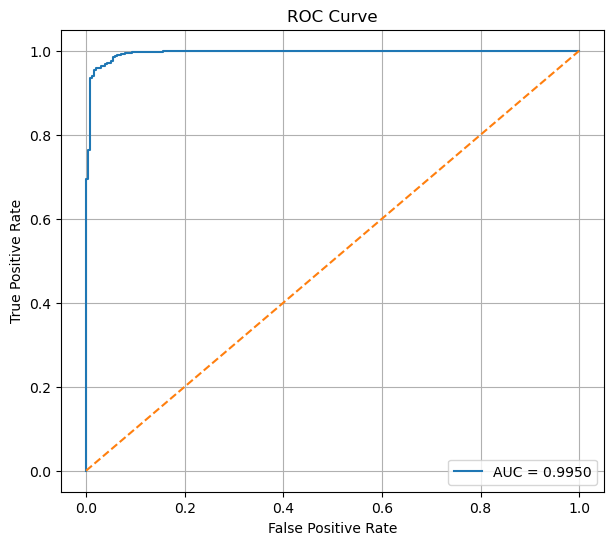


ROC-AUC Score: 0.995


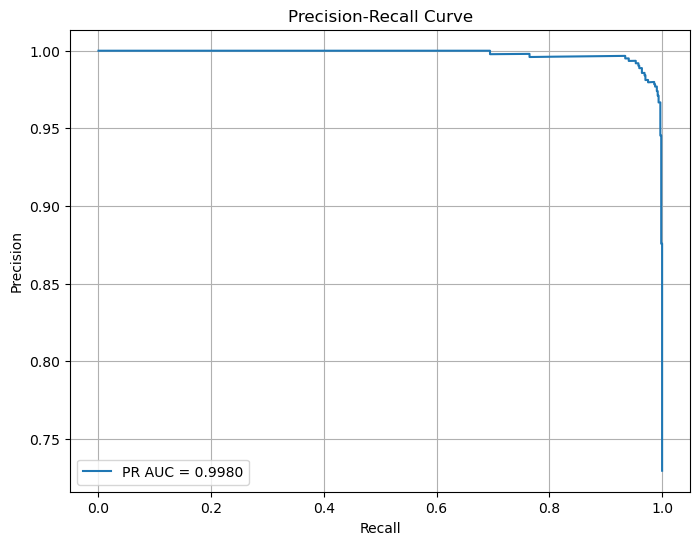

PR-AUC Score: 0.998
28/28 ━━━━━━━━━━━━━━━━━━━━ 254s 9s/step

Total Inference Time: 256.0572 seconds
Time per Image: 0.290974 seconds


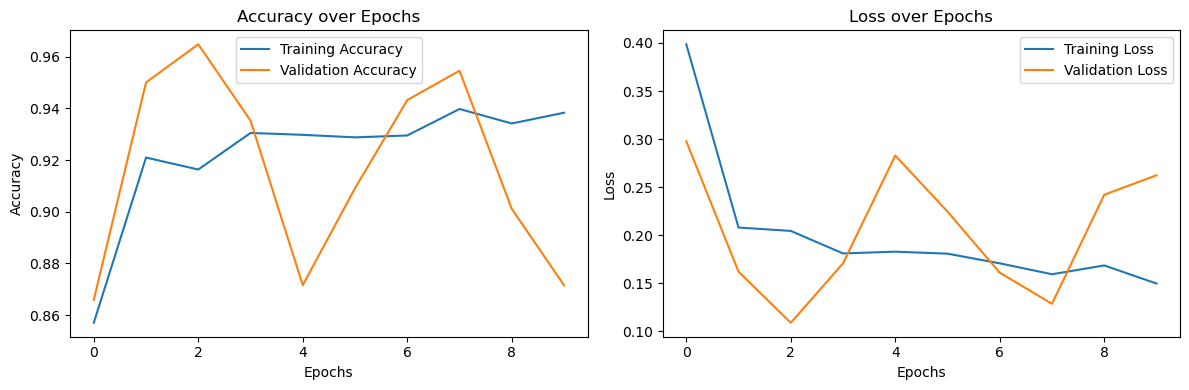


Model Saved Successfully!


In [7]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)

from sklearn.utils.class_weight import compute_class_weight

# =========================================================
# 1. DATASET PATHS
# =========================================================

train_path = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\train"
val_path   = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\val"
test_path  = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\test"

# =========================================================
# 2. IMAGE PARAMETERS
# =========================================================

IMG_SIZE = 224
BATCH_SIZE = 32

# =========================================================
# 3. DATA AUGMENTATION
# =========================================================

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.1,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

# =========================================================
# 4. LOAD DATASET
# =========================================================

train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

val_data = test_datagen.flow_from_directory(
    val_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

# =========================================================
# 5. COMPUTE CLASS WEIGHTS
# =========================================================

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_data.classes),
    y=train_data.classes
)

class_weights = dict(enumerate(class_weights))

print("\nClass Weights:")
print(class_weights)

# =========================================================
# 6. LOAD VGG16 MODEL
# =========================================================

base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
for layer in base_model.layers:
    layer.trainable = False

# =========================================================
# 7. BUILD MODEL
# =========================================================

model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# =========================================================
# 8. COMPILE MODEL
# =========================================================

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================================================
# 9. TRAIN MODEL
# =========================================================

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    class_weight=class_weights
)

# =========================================================
# 10. EVALUATE MODEL
# =========================================================

test_loss, test_accuracy = model.evaluate(test_data)

print("\nTest Accuracy:", round(test_accuracy, 4))

# =========================================================
# 11. PREDICTIONS
# =========================================================

y_prob = model.predict(test_data)

y_pred = (y_prob > 0.5).astype(int)

y_true = test_data.classes

# =========================================================
# 12. CLASSIFICATION REPORT
# =========================================================

print("\nClassification Report:\n")

target_names = ['NORMAL', 'PNEUMONIA']

print(classification_report(
    y_true,
    y_pred,
    target_names=target_names
))

# =========================================================
# 13. CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:\n")
print(cm)

# Plot Confusion Matrix

plt.figure(figsize=(6,6))

plt.imshow(cm, cmap='Blues')

plt.title('Confusion Matrix')

plt.colorbar()

classes = ['NORMAL', 'PNEUMONIA']

tick_marks = np.arange(len(classes))

plt.xticks(tick_marks, classes)
plt.yticks(tick_marks, classes)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(
            j,
            i,
            cm[i, j],
            ha='center',
            va='center',
            color='red'
        )

plt.show()

# =========================================================
# 14. SENSITIVITY & SPECIFICITY
# =========================================================

tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn)

specificity = tn / (tn + fp)

print("Sensitivity:", round(sensitivity, 4))

print("Specificity:", round(specificity, 4))

# =========================================================
# 15. ROC CURVE
# =========================================================

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))

plt.plot(fpr, tpr, label='AUC = %0.4f' % roc_auc)

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel('False Positive Rate')

plt.ylabel('True Positive Rate')

plt.title('ROC Curve')

plt.legend(loc='lower right')

plt.grid(True)

plt.show()

print("\nROC-AUC Score:", round(roc_auc, 4))

# =========================================================
# 16. PRECISION-RECALL CURVE
# =========================================================

precision, recall, thresholds = precision_recall_curve(
    y_true,
    y_prob
)

pr_auc = auc(recall, precision)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f'PR AUC = {pr_auc:.4f}'
)

plt.xlabel('Recall')

plt.ylabel('Precision')

plt.title('Precision-Recall Curve')

plt.legend(loc='lower left')

plt.grid(True)

plt.show()

print("PR-AUC Score:", round(pr_auc, 4))

# =========================================================
# 17. INFERENCE TIME
# =========================================================

start = time.time()

_ = model.predict(test_data)

end = time.time()

total_time = end - start

avg_time = total_time / test_data.samples

print("\nTotal Inference Time:", round(total_time, 4), "seconds")

print("Time per Image:", round(avg_time, 6), "seconds")

# =========================================================
# 18. TRAINING & VALIDATION CURVES
# =========================================================

plt.figure(figsize=(12, 4))

# Accuracy Plot

plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('Accuracy over Epochs')

plt.xlabel('Epochs')

plt.ylabel('Accuracy')

plt.legend()

# Loss Plot

plt.subplot(1, 2, 2)

plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.title('Loss over Epochs')

plt.xlabel('Epochs')

plt.ylabel('Loss')

plt.legend()

plt.tight_layout()

plt.show()

# =========================================================
# 19. SAVE MODEL
# =========================================================

model.save("pneumonia_vgg16_model.h5")

print("\nModel Saved Successfully!")

Found 4099 images belonging to 2 classes.
Found 880 images belonging to 2 classes.
Found 880 images belonging to 2 classes.

Class Weights:
{0: 1.8497292418772564, 1: 0.6852223336676697}
Epoch 1/20


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


129/129 ━━━━━━━━━━━━━━━━━━━━ 1328s 10s/step - accuracy: 0.8068 - loss: 0.6568 - val_accuracy: 0.8955 - val_loss: 0.2521
Epoch 2/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 1593s 12s/step - accuracy: 0.9156 - loss: 0.2048 - val_accuracy: 0.9568 - val_loss: 0.1374
Epoch 3/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 1595s 12s/step - accuracy: 0.9270 - loss: 0.1893 - val_accuracy: 0.7205 - val_loss: 0.6606
Epoch 4/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 1657s 13s/step - accuracy: 0.8968 - loss: 0.2357 - val_accuracy: 0.9545 - val_loss: 0.1363
Epoch 5/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 1458s 11s/step - accuracy: 0.9306 - loss: 0.1757 - val_accuracy: 0.9523 - val_loss: 0.1421
Epoch 6/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 1390s 11s/step - accuracy: 0.9360 - loss: 0.1735 - val_accuracy: 0.9477 - val_loss: 0.1447
Epoch 7/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 1678s 13s/step - accuracy: 0.9493 - loss: 0.1433 - val_accuracy: 0.8795 - val_loss: 0.2639
Epoch 8/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 1601s 12s/step - accuracy: 0.9345 - loss: 0.1644 - val

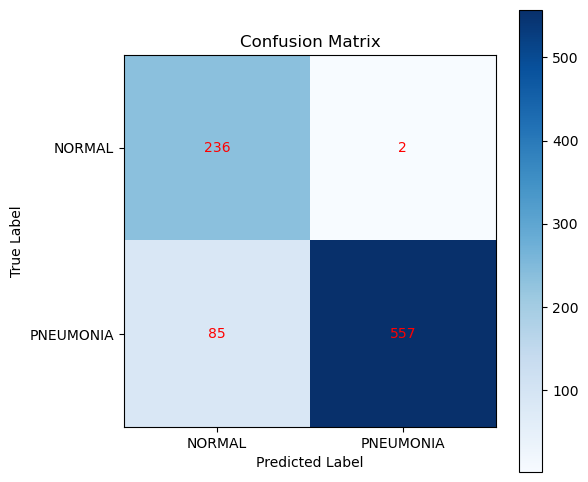

Sensitivity: 0.8676
Specificity: 0.9916


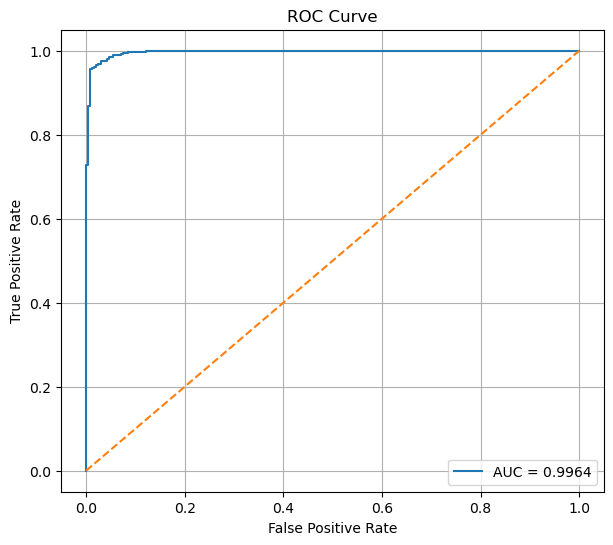


ROC-AUC Score: 0.9964


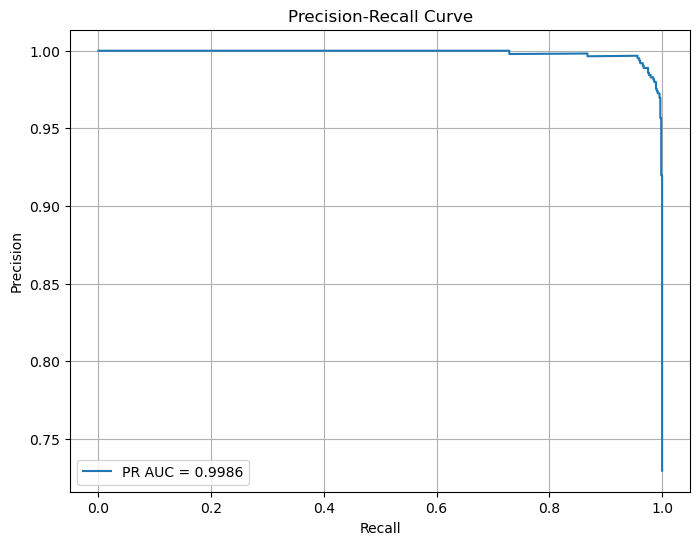

PR-AUC Score: 0.9986
28/28 ━━━━━━━━━━━━━━━━━━━━ 240s 9s/step

Total Inference Time: 241.8908 seconds
Time per Image: 0.274876 seconds


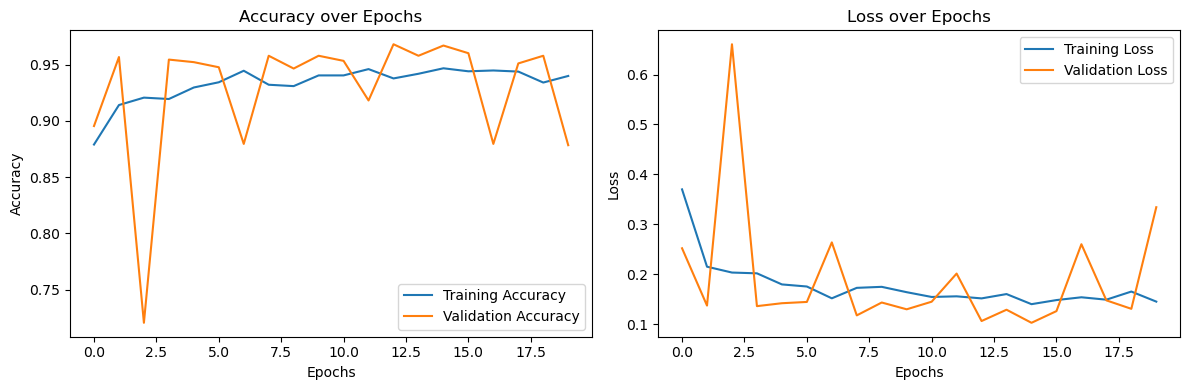


Model Saved Successfully!


In [9]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)

from sklearn.utils.class_weight import compute_class_weight

# =========================================================
# 1. DATASET PATHS
# =========================================================

train_path = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\train"
val_path   = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\val"
test_path  = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\test"

# =========================================================
# 2. IMAGE PARAMETERS
# =========================================================

IMG_SIZE = 224
BATCH_SIZE = 32

# =========================================================
# 3. DATA AUGMENTATION
# =========================================================

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.1,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

# =========================================================
# 4. LOAD DATASET
# =========================================================

train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

val_data = test_datagen.flow_from_directory(
    val_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

# =========================================================
# 5. COMPUTE CLASS WEIGHTS
# =========================================================

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_data.classes),
    y=train_data.classes
)

class_weights = dict(enumerate(class_weights))

print("\nClass Weights:")
print(class_weights)

# =========================================================
# 6. LOAD VGG16 MODEL
# =========================================================

base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
for layer in base_model.layers:
    layer.trainable = False

# =========================================================
# 7. BUILD MODEL
# =========================================================

model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# =========================================================
# 8. COMPILE MODEL
# =========================================================

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================================================
# 9. TRAIN MODEL
# =========================================================

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    class_weight=class_weights
)

# =========================================================
# 10. EVALUATE MODEL
# =========================================================

test_loss, test_accuracy = model.evaluate(test_data)

print("\nTest Accuracy:", round(test_accuracy, 4))

# =========================================================
# 11. PREDICTIONS
# =========================================================

y_prob = model.predict(test_data)

y_pred = (y_prob > 0.5).astype(int)

y_true = test_data.classes

# =========================================================
# 12. CLASSIFICATION REPORT
# =========================================================

print("\nClassification Report:\n")

target_names = ['NORMAL', 'PNEUMONIA']

print(classification_report(
    y_true,
    y_pred,
    target_names=target_names
))

# =========================================================
# 13. CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:\n")
print(cm)

# Plot Confusion Matrix

plt.figure(figsize=(6,6))

plt.imshow(cm, cmap='Blues')

plt.title('Confusion Matrix')

plt.colorbar()

classes = ['NORMAL', 'PNEUMONIA']

tick_marks = np.arange(len(classes))

plt.xticks(tick_marks, classes)
plt.yticks(tick_marks, classes)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(
            j,
            i,
            cm[i, j],
            ha='center',
            va='center',
            color='red'
        )

plt.show()

# =========================================================
# 14. SENSITIVITY & SPECIFICITY
# =========================================================

tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn)

specificity = tn / (tn + fp)

print("Sensitivity:", round(sensitivity, 4))

print("Specificity:", round(specificity, 4))

# =========================================================
# 15. ROC CURVE
# =========================================================

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))

plt.plot(fpr, tpr, label='AUC = %0.4f' % roc_auc)

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel('False Positive Rate')

plt.ylabel('True Positive Rate')

plt.title('ROC Curve')

plt.legend(loc='lower right')

plt.grid(True)

plt.show()

print("\nROC-AUC Score:", round(roc_auc, 4))

# =========================================================
# 16. PRECISION-RECALL CURVE
# =========================================================

precision, recall, thresholds = precision_recall_curve(
    y_true,
    y_prob
)

pr_auc = auc(recall, precision)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f'PR AUC = {pr_auc:.4f}'
)

plt.xlabel('Recall')

plt.ylabel('Precision')

plt.title('Precision-Recall Curve')

plt.legend(loc='lower left')

plt.grid(True)

plt.show()

print("PR-AUC Score:", round(pr_auc, 4))

# =========================================================
# 17. INFERENCE TIME
# =========================================================

start = time.time()

_ = model.predict(test_data)

end = time.time()

total_time = end - start

avg_time = total_time / test_data.samples

print("\nTotal Inference Time:", round(total_time, 4), "seconds")

print("Time per Image:", round(avg_time, 6), "seconds")

# =========================================================
# 18. TRAINING & VALIDATION CURVES
# =========================================================

plt.figure(figsize=(12, 4))

# Accuracy Plot

plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('Accuracy over Epochs')

plt.xlabel('Epochs')

plt.ylabel('Accuracy')

plt.legend()

# Loss Plot

plt.subplot(1, 2, 2)

plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.title('Loss over Epochs')

plt.xlabel('Epochs')

plt.ylabel('Loss')

plt.legend()

plt.tight_layout()

plt.show()

# =========================================================
# 19. SAVE MODEL
# =========================================================

model.save("pneumonia_vgg16 20Epochs_model.h5")

print("\nModel Saved Successfully!")

In [173]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Libraries loaded successfully.")

TensorFlow version: 2.17.0
Libraries loaded successfully.


In [174]:
model = tf.keras.models.load_model(
    "pneumonia_vgg16 20Epochs_model.h5"
)

print("Model loaded successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [175]:
base_model = model.layers[0]

print("Base model:", base_model.name)
print("Base model output shape:", base_model.output_shape)

Base model: vgg16
Base model output shape: (None, 7, 7, 512)


In [176]:
target_layer = base_model.get_layer("block5_conv3")

print("Grad-CAM layer:", target_layer.name)
print("Number of filters:", target_layer.filters)

Grad-CAM layer: block5_conv3
Number of filters: 512


In [177]:
def preprocess_image(path):
    img = tf.keras.preprocessing.image.load_img(
        path,
        target_size=(224, 224)
    )

    img = tf.keras.preprocessing.image.img_to_array(img)

    img = np.expand_dims(img, axis=0)

    img = img / 255.0

    return img

In [178]:
img_path = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\test\PNEUMONIA\person15_virus_46.jpeg"

img_array = preprocess_image(img_path)

print("Image prepared successfully.")
print("Image shape:", img_array.shape)
print("Minimum pixel value:", img_array.min())
print("Maximum pixel value:", img_array.max())

Image prepared successfully.
Image shape: (1, 224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [131]:
prediction = model.predict(img_array, verbose=0)

probability = float(prediction[0][0])

print("Prediction probability:", probability)

if probability >= 0.5:
    predicted_class = "Pneumonia"
else:
    predicted_class = "Normal"

print("Predicted class:", predicted_class)

Prediction probability: 0.11761463433504105
Predicted class: Normal


In [132]:
def gradcam(img_array):

    # Select the target convolutional layer
    target_layer = base_model.get_layer("block5_conv3")

    # Create a model that returns:
    # 1. target convolutional feature maps
    # 2. VGG16 feature output
    grad_model = tf.keras.models.Model(
        inputs=base_model.input,
        outputs=[target_layer.output, base_model.output]
    )

    with tf.GradientTape() as tape:

        # Forward pass through VGG16
        conv_outputs, base_output = grad_model(
            img_array,
            training=False
        )

        # Pass VGG16 features through the classifier
        x = base_output

        for layer in model.layers[1:]:
            x = layer(x, training=False)

        predictions = x[:, 0]

        # Explain the predicted class
        if float(predictions[0]) >= 0.5:
            target = predictions
        else:
            target = 1.0 - predictions

    # Calculate gradients
    grads = tape.gradient(
        target,
        conv_outputs
    )

    # Global average pooling of gradients
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]

    # Weight feature maps by their gradients
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize for visualization
    heatmap = heatmap / (
        tf.reduce_max(heatmap)
        + tf.keras.backend.epsilon()
    )

    return heatmap.numpy()

In [133]:
heatmap = gradcam(img_array)

print("Heatmap generated successfully.")
print("Heatmap shape:", heatmap.shape)
print("Heatmap minimum:", heatmap.min())
print("Heatmap maximum:", heatmap.max())

Heatmap generated successfully.
Heatmap shape: (14, 14)
Heatmap minimum: 0.0
Heatmap maximum: 0.9999686


In [134]:
def show_gradcam(img_path, heatmap):

    # Load original X-ray
    original = cv2.imread(img_path)
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    original = cv2.resize(original, (224, 224))

    # Resize Grad-CAM heatmap
    heatmap_resized = cv2.resize(
        heatmap,
        (224, 224),
        interpolation=cv2.INTER_LINEAR
    )

    # Convert heatmap to 0–255
    heatmap_uint8 = np.uint8(255 * heatmap_resized)

    # Apply JET colormap
    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    # Convert BGR to RGB
    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # Create overlay
    overlay = cv2.addWeighted(
        original,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    # Create figure
    plt.figure(figsize=(15, 5))

    # 1. Original X-ray
    plt.subplot(1, 3, 1)
    plt.imshow(original)
    plt.title("Original X-ray", fontsize=14)
    plt.axis("off")

    # 2. Grad-CAM heatmap
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM Heatmap", fontsize=14)
    plt.axis("off")

    # 3. Grad-CAM overlay
    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title("Grad-CAM Overlay", fontsize=14)
    plt.axis("off")

    plt.tight_layout()
    plt.show()

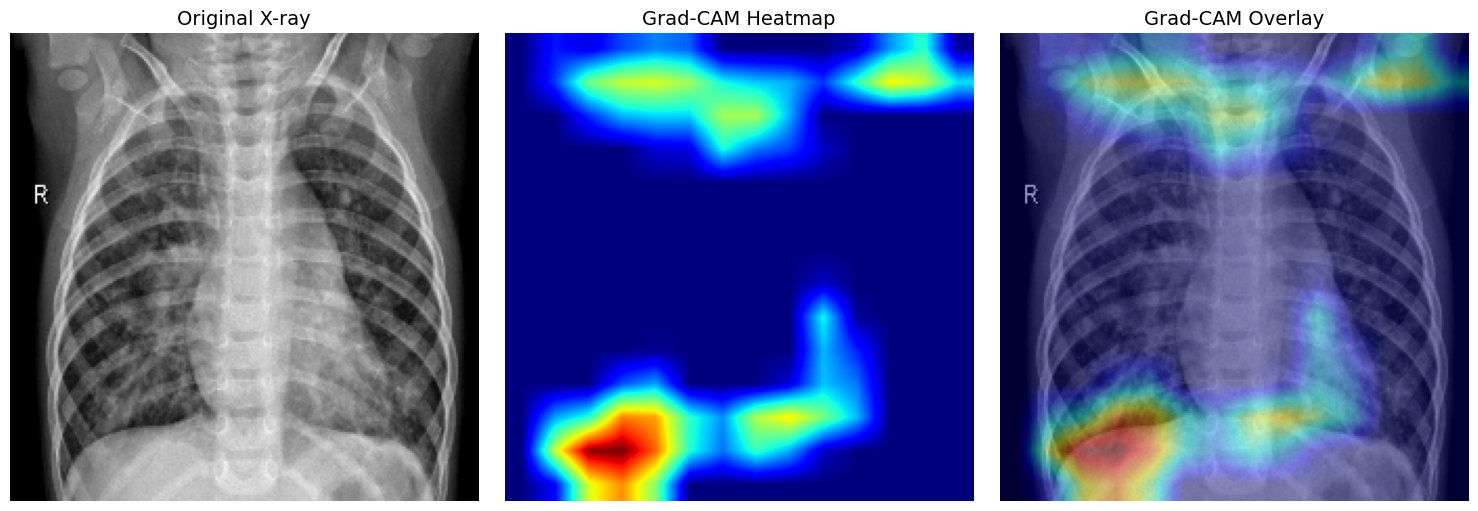

In [135]:
show_gradcam(img_path, heatmap)

Found 4099 images belonging to 2 classes.
Found 880 images belonging to 2 classes.
Found 880 images belonging to 2 classes.

Class Weights:
{0: 1.8497292418772564, 1: 0.6852223336676697}
Epoch 1/20


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


129/129 ━━━━━━━━━━━━━━━━━━━━ 469s 3s/step - accuracy: 0.7878 - loss: 0.4539 - val_accuracy: 0.8943 - val_loss: 0.2605
Epoch 2/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 446s 3s/step - accuracy: 0.8762 - loss: 0.2710 - val_accuracy: 0.8909 - val_loss: 0.2619
Epoch 3/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 448s 3s/step - accuracy: 0.9047 - loss: 0.2285 - val_accuracy: 0.9295 - val_loss: 0.1857
Epoch 4/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 448s 3s/step - accuracy: 0.9251 - loss: 0.2121 - val_accuracy: 0.8830 - val_loss: 0.2784
Epoch 5/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 451s 3s/step - accuracy: 0.9235 - loss: 0.1877 - val_accuracy: 0.9500 - val_loss: 0.1489
Epoch 6/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 448s 3s/step - accuracy: 0.9178 - loss: 0.1959 - val_accuracy: 0.9136 - val_loss: 0.2103
Epoch 7/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 447s 3s/step - accuracy: 0.9215 - loss: 0.1904 - val_accuracy: 0.8682 - val_loss: 0.3416
Epoch 8/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 449s 3s/step - accuracy: 0.8963 - loss: 0.2267 - val_accuracy: 0.940

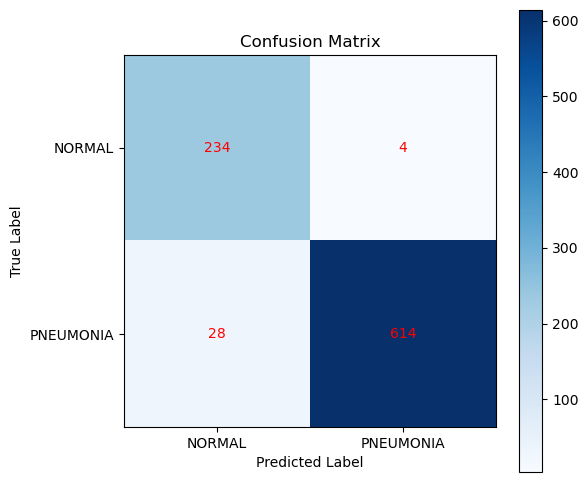

Sensitivity: 0.9564
Specificity: 0.9832


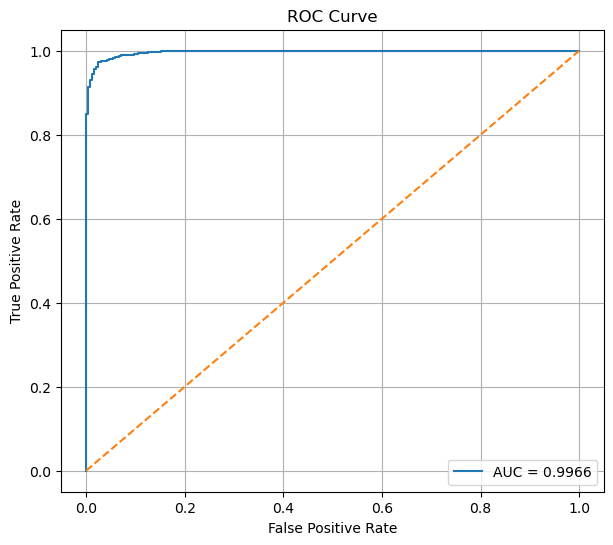


ROC-AUC Score: 0.9966


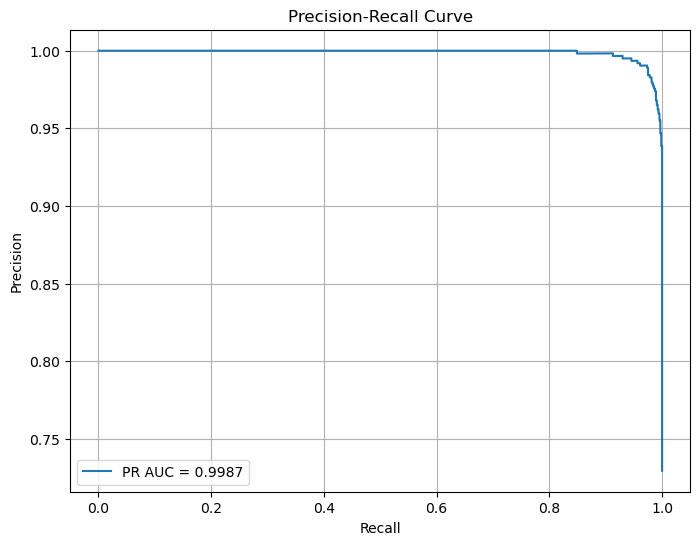

PR-AUC Score: 0.9987
28/28 ━━━━━━━━━━━━━━━━━━━━ 76s 3s/step

Total Inference Time: 77.7525 seconds
Time per Image: 0.088355 seconds


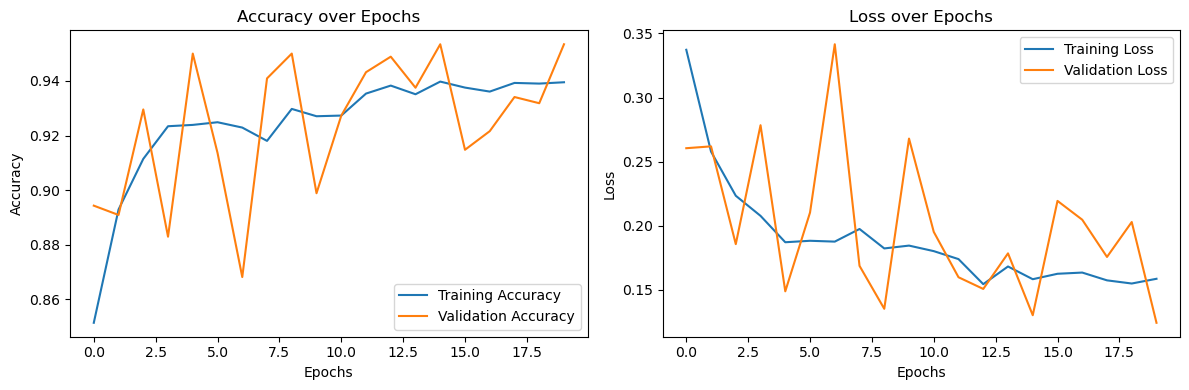


Model Saved Successfully!


In [10]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)

from sklearn.utils.class_weight import compute_class_weight

# =========================================================
# 1. DATASET PATHS
# =========================================================

train_path = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\train"
val_path   = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\val"
test_path  = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\test"

# =========================================================
# 2. IMAGE PARAMETERS
# =========================================================

IMG_SIZE = 224
BATCH_SIZE = 32

# =========================================================
# 3. DATA AUGMENTATION
# =========================================================

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.1,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

# =========================================================
# 4. LOAD DATASET
# =========================================================

train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

val_data = test_datagen.flow_from_directory(
    val_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

# =========================================================
# 5. COMPUTE CLASS WEIGHTS
# =========================================================

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_data.classes),
    y=train_data.classes
)

class_weights = dict(enumerate(class_weights))

print("\nClass Weights:")
print(class_weights)

# =========================================================
# 6. LOAD DENSENET121 MODEL
# =========================================================

base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
for layer in base_model.layers:
    layer.trainable = False

# =========================================================
# 7. BUILD MODEL
# =========================================================

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# =========================================================
# 8. COMPILE MODEL
# =========================================================

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================================================
# 9. TRAIN MODEL
# =========================================================

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    class_weight=class_weights
)

# =========================================================
# 10. EVALUATE MODEL
# =========================================================

test_loss, test_accuracy = model.evaluate(test_data)

print("\nTest Accuracy:", round(test_accuracy, 4))

# =========================================================
# 11. PREDICTIONS
# =========================================================

y_prob = model.predict(test_data)
y_pred = (y_prob > 0.5).astype(int)
y_true = test_data.classes

# =========================================================
# 12. CLASSIFICATION REPORT
# =========================================================

target_names = ['NORMAL', 'PNEUMONIA']

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=target_names
))

# =========================================================
# 13. CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:\n")
print(cm)

plt.figure(figsize=(6,6))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.colorbar()

classes = ['NORMAL', 'PNEUMONIA']
tick_marks = np.arange(len(classes))

plt.xticks(tick_marks, classes)
plt.yticks(tick_marks, classes)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, cm[i, j],
                 ha='center', va='center', color='red')

plt.show()

# =========================================================
# 14. SENSITIVITY & SPECIFICITY
# =========================================================

tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))

# =========================================================
# 15. ROC CURVE
# =========================================================

fpr, tpr, thresholds = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, label='AUC = %0.4f' % roc_auc)
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print("\nROC-AUC Score:", round(roc_auc, 4))

# =========================================================
# 16. PRECISION-RECALL CURVE
# =========================================================

precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
pr_auc = auc(recall, precision)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'PR AUC = {pr_auc:.4f}')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

print("PR-AUC Score:", round(pr_auc, 4))

# =========================================================
# 17. INFERENCE TIME
# =========================================================

start = time.time()
_ = model.predict(test_data)
end = time.time()

total_time = end - start
avg_time = total_time / test_data.samples

print("\nTotal Inference Time:", round(total_time, 4), "seconds")
print("Time per Image:", round(avg_time, 6), "seconds")

# =========================================================
# 18. TRAINING CURVES
# =========================================================

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# =========================================================
# 19. SAVE MODEL
# =========================================================

model.save("pneumonia_densenet121_20Epochs_model.h5")

print("\nModel Saved Successfully!")

In [1]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Libraries loaded successfully.")

C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


TensorFlow version: 2.17.0
Libraries loaded successfully.


In [2]:
model = tf.keras.models.load_model(
    "pneumonia_densenet121_20Epochs_model.h5"
)

print("Model loaded successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [3]:
base_model = model.layers[0]

print("Base model:", base_model.name)
print("Number of layers:", len(base_model.layers))
print("Base model output shape:", base_model.output_shape)

Base model: densenet121
Number of layers: 427
Base model output shape: (None, 7, 7, 1024)


In [4]:
for layer in base_model.layers[-30:]:
    print(layer.name, "->", layer.__class__.__name__)

conv5_block13_0_bn -> BatchNormalization
conv5_block13_0_relu -> Activation
conv5_block13_1_conv -> Conv2D
conv5_block13_1_bn -> BatchNormalization
conv5_block13_1_relu -> Activation
conv5_block13_2_conv -> Conv2D
conv5_block13_concat -> Concatenate
conv5_block14_0_bn -> BatchNormalization
conv5_block14_0_relu -> Activation
conv5_block14_1_conv -> Conv2D
conv5_block14_1_bn -> BatchNormalization
conv5_block14_1_relu -> Activation
conv5_block14_2_conv -> Conv2D
conv5_block14_concat -> Concatenate
conv5_block15_0_bn -> BatchNormalization
conv5_block15_0_relu -> Activation
conv5_block15_1_conv -> Conv2D
conv5_block15_1_bn -> BatchNormalization
conv5_block15_1_relu -> Activation
conv5_block15_2_conv -> Conv2D
conv5_block15_concat -> Concatenate
conv5_block16_0_bn -> BatchNormalization
conv5_block16_0_relu -> Activation
conv5_block16_1_conv -> Conv2D
conv5_block16_1_bn -> BatchNormalization
conv5_block16_1_relu -> Activation
conv5_block16_2_conv -> Conv2D
conv5_block16_concat -> Concatenate


In [5]:
target_layer = base_model.get_layer("conv5_block16_2_conv")

print("Grad-CAM layer:", target_layer.name)
print("Number of filters:", target_layer.filters)

Grad-CAM layer: conv5_block16_2_conv
Number of filters: 32


Found 4099 images belonging to 2 classes.
Found 880 images belonging to 2 classes.
Found 880 images belonging to 2 classes.

Class Weights:
{0: 1.8497292418772564, 1: 0.6852223336676697}
Epoch 1/20


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


129/129 ━━━━━━━━━━━━━━━━━━━━ 292s 2s/step - accuracy: 0.8220 - loss: 0.3712 - val_accuracy: 0.9466 - val_loss: 0.1341
Epoch 2/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 271s 2s/step - accuracy: 0.9106 - loss: 0.2049 - val_accuracy: 0.9341 - val_loss: 0.1674
Epoch 3/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 231s 2s/step - accuracy: 0.9214 - loss: 0.1935 - val_accuracy: 0.9114 - val_loss: 0.2227
Epoch 4/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 230s 2s/step - accuracy: 0.9357 - loss: 0.1579 - val_accuracy: 0.9500 - val_loss: 0.1208
Epoch 5/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 234s 2s/step - accuracy: 0.9400 - loss: 0.1622 - val_accuracy: 0.9364 - val_loss: 0.1763
Epoch 6/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 230s 2s/step - accuracy: 0.9384 - loss: 0.1519 - val_accuracy: 0.9602 - val_loss: 0.1112
Epoch 7/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 230s 2s/step - accuracy: 0.9388 - loss: 0.1506 - val_accuracy: 0.9466 - val_loss: 0.1456
Epoch 8/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 246s 2s/step - accuracy: 0.9426 - loss: 0.1487 - val_accuracy: 0.938

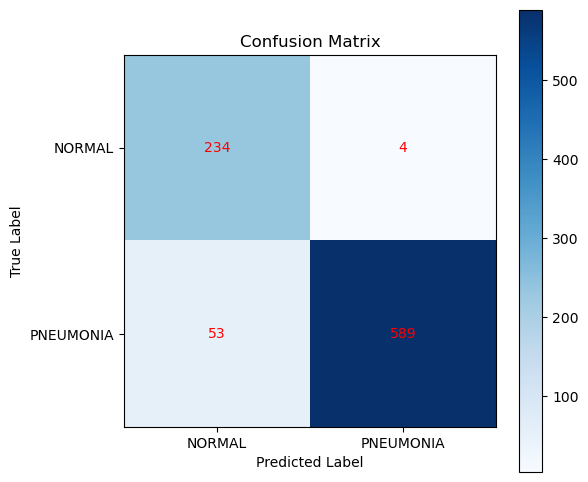

Sensitivity: 0.9174
Specificity: 0.9832


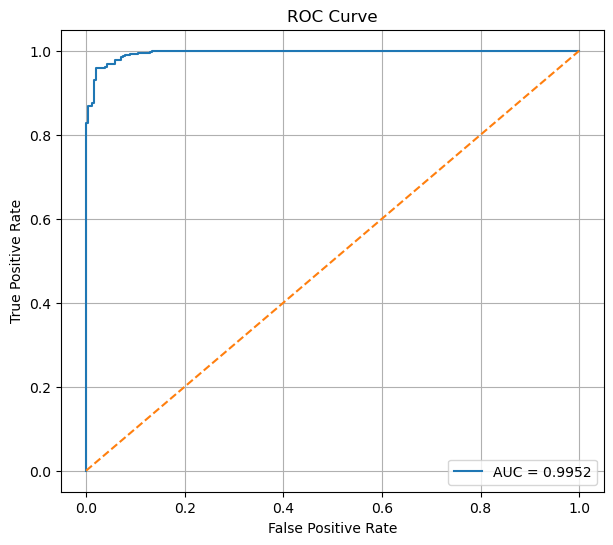


ROC-AUC Score: 0.9952


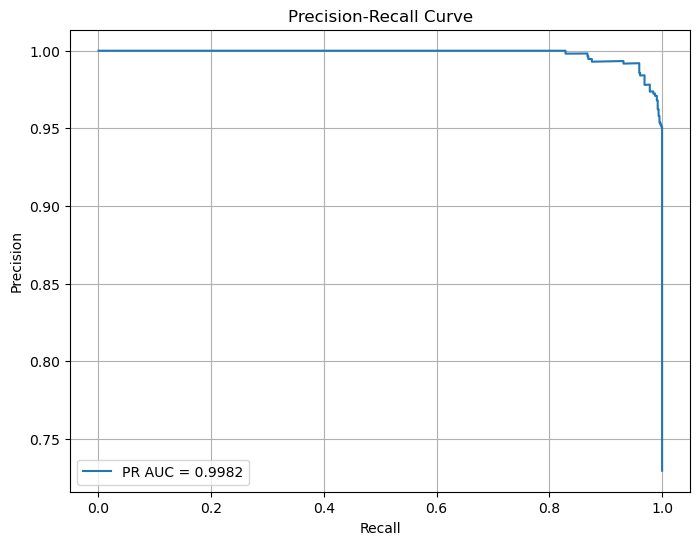

PR-AUC Score: 0.9982
28/28 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step

Total Inference Time: 44.3908 seconds
Time per Image: 0.050444 seconds


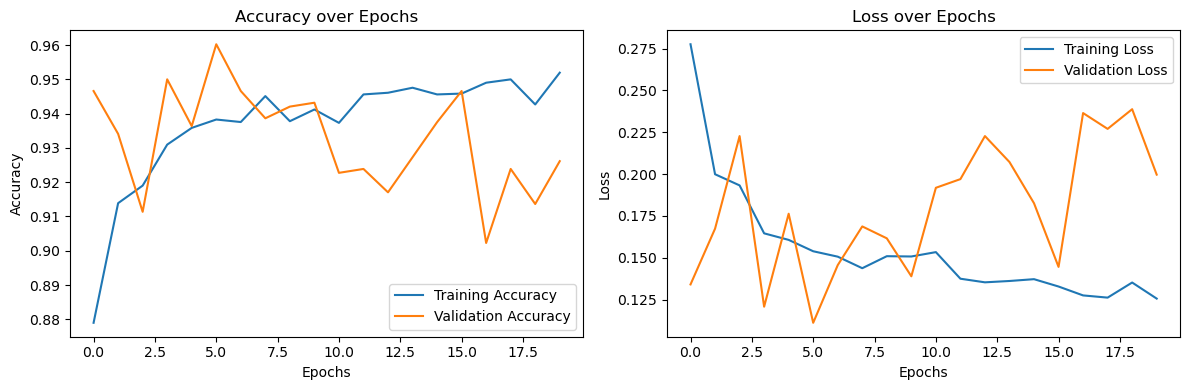


Model Saved Successfully!


In [11]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)

from sklearn.utils.class_weight import compute_class_weight

# =========================================================
# 1. DATASET PATHS
# =========================================================

train_path = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\train"
val_path   = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\val"
test_path  = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\test"

# =========================================================
# 2. IMAGE PARAMETERS
# =========================================================

IMG_SIZE = 224
BATCH_SIZE = 32

# =========================================================
# 3. DATA AUGMENTATION
# =========================================================

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.1,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

# =========================================================
# 4. LOAD DATASET
# =========================================================

train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

val_data = test_datagen.flow_from_directory(
    val_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

# =========================================================
# 5. COMPUTE CLASS WEIGHTS
# =========================================================

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_data.classes),
    y=train_data.classes
)

class_weights = dict(enumerate(class_weights))

print("\nClass Weights:")
print(class_weights)

# =========================================================
# 6. LOAD MOBILE NET V2 MODEL
# =========================================================

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
for layer in base_model.layers:
    layer.trainable = False

# =========================================================
# 7. BUILD MODEL
# =========================================================

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# =========================================================
# 8. COMPILE MODEL
# =========================================================

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================================================
# 9. TRAIN MODEL
# =========================================================

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    class_weight=class_weights
)

# =========================================================
# 10. EVALUATE MODEL
# =========================================================

test_loss, test_accuracy = model.evaluate(test_data)
print("\nTest Accuracy:", round(test_accuracy, 4))

# =========================================================
# 11. PREDICTIONS
# =========================================================

y_prob = model.predict(test_data)
y_pred = (y_prob > 0.5).astype(int)
y_true = test_data.classes

# =========================================================
# 12. CLASSIFICATION REPORT
# =========================================================

target_names = ['NORMAL', 'PNEUMONIA']

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=target_names
))

# =========================================================
# 13. CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:\n")
print(cm)

plt.figure(figsize=(6,6))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.colorbar()

classes = ['NORMAL', 'PNEUMONIA']
tick_marks = np.arange(len(classes))

plt.xticks(tick_marks, classes)
plt.yticks(tick_marks, classes)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, cm[i, j],
                 ha='center', va='center', color='red')

plt.show()

# =========================================================
# 14. SENSITIVITY & SPECIFICITY
# =========================================================

tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))

# =========================================================
# 15. ROC CURVE
# =========================================================

fpr, tpr, thresholds = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, label='AUC = %0.4f' % roc_auc)
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print("\nROC-AUC Score:", round(roc_auc, 4))

# =========================================================
# 16. PRECISION-RECALL CURVE
# =========================================================

precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
pr_auc = auc(recall, precision)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'PR AUC = {pr_auc:.4f}')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

print("PR-AUC Score:", round(pr_auc, 4))

# =========================================================
# 17. INFERENCE TIME
# =========================================================

start = time.time()
_ = model.predict(test_data)
end = time.time()

total_time = end - start
avg_time = total_time / test_data.samples

print("\nTotal Inference Time:", round(total_time, 4), "seconds")
print("Time per Image:", round(avg_time, 6), "seconds")

# =========================================================
# 18. TRAINING CURVES
# =========================================================

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# =========================================================
# 19. SAVE MODEL
# =========================================================

model.save("pneumonia_mobilenetv2_20Epochs_model.h5")

print("\nModel Saved Successfully!")

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Dense,
    Dropout,
    Flatten,
    BatchNormalization
)

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)

from sklearn.utils.class_weight import compute_class_weight

# =========================================================
# 1. DATASET PATHS
# =========================================================

train_path = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\train"
val_path   = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\val"
test_path  = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\test"

# =========================================================
# 2. IMAGE PARAMETERS
# =========================================================

IMG_SIZE = 224
BATCH_SIZE = 32

# =========================================================
# 3. DATA AUGMENTATION
# =========================================================

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.1,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

# =========================================================
# 4. LOAD DATASET
# =========================================================

train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

val_data = test_datagen.flow_from_directory(
    val_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

# =========================================================
# 5. COMPUTE CLASS WEIGHTS
# =========================================================

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_data.classes),
    y=train_data.classes
)

class_weights = dict(enumerate(class_weights))

print("\nClass Weights:")
print(class_weights)

# =========================================================
# 6. BUILD CNN MODEL
# =========================================================

model = Sequential([

    # First Convolution Block
    Conv2D(
        32,
        (3,3),
        activation='relu',
        padding='same',
        input_shape=(224,224,3)
    ),

    BatchNormalization(),

    MaxPooling2D((2,2)),

    # Second Convolution Block
    Conv2D(
        64,
        (3,3),
        activation='relu',
        padding='same'
    ),

    BatchNormalization(),

    MaxPooling2D((2,2)),

    # Third Convolution Block
    Conv2D(
        128,
        (3,3),
        activation='relu',
        padding='same'
    ),

    BatchNormalization(),

    MaxPooling2D((2,2)),

    # Fourth Convolution Block
    Conv2D(
        256,
        (3,3),
        activation='relu',
        padding='same'
    ),

    BatchNormalization(),

    MaxPooling2D((2,2)),

    # Flatten Layer
    Flatten(),

    # Fully Connected Layer
    Dense(256, activation='relu'),

    Dropout(0.5),

    # Output Layer
    Dense(1, activation='sigmoid')
])

# =========================================================
# 7. COMPILE MODEL
# =========================================================

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================================================
# 8. MODEL SUMMARY
# =========================================================

model.summary()

# =========================================================
# 9. TRAIN MODEL
# =========================================================

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    class_weight=class_weights
)

# =========================================================
# 10. EVALUATE MODEL
# =========================================================

test_loss, test_accuracy = model.evaluate(test_data)

print("\nTest Accuracy:", round(test_accuracy, 4))

# =========================================================
# 11. PREDICTIONS
# =========================================================

y_prob = model.predict(test_data)

y_pred = (y_prob > 0.5).astype(int)

y_true = test_data.classes

# =========================================================
# 12. CLASSIFICATION REPORT
# =========================================================

print("\nClassification Report:\n")

target_names = ['NORMAL', 'PNEUMONIA']

print(classification_report(
    y_true,
    y_pred,
    target_names=target_names
))

# =========================================================
# 13. CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:\n")
print(cm)

# Plot Confusion Matrix

plt.figure(figsize=(6,6))

plt.imshow(cm, cmap='Blues')

plt.title('Confusion Matrix')

plt.colorbar()

classes = ['NORMAL', 'PNEUMONIA']

tick_marks = np.arange(len(classes))

plt.xticks(tick_marks, classes)
plt.yticks(tick_marks, classes)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(
            j,
            i,
            cm[i, j],
            ha='center',
            va='center',
            color='red'
        )

plt.show()

# =========================================================
# 14. SENSITIVITY & SPECIFICITY
# =========================================================

tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn)

specificity = tn / (tn + fp)

print("Sensitivity:", round(sensitivity, 4))

print("Specificity:", round(specificity, 4))

# =========================================================
# 15. ROC CURVE
# =========================================================

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))

plt.plot(fpr, tpr, label='AUC = %0.4f' % roc_auc)

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel('False Positive Rate')

plt.ylabel('True Positive Rate')

plt.title('ROC Curve')

plt.legend(loc='lower right')

plt.grid(True)

plt.show()

print("\nROC-AUC Score:", round(roc_auc, 4))

# =========================================================
# 16. PRECISION-RECALL CURVE
# =========================================================

precision, recall, thresholds = precision_recall_curve(
    y_true,
    y_prob
)

pr_auc = auc(recall, precision)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f'PR AUC = {pr_auc:.4f}'
)

plt.xlabel('Recall')

plt.ylabel('Precision')

plt.title('Precision-Recall Curve')

plt.legend(loc='lower left')

plt.grid(True)

plt.show()

print("PR-AUC Score:", round(pr_auc, 4))

# =========================================================
# 17. INFERENCE TIME
# =========================================================

start = time.time()

_ = model.predict(test_data)

end = time.time()

total_time = end - start

avg_time = total_time / test_data.samples

print("\nTotal Inference Time:", round(total_time, 4), "seconds")

print("Time per Image:", round(avg_time, 6), "seconds")

# =========================================================
# 18. TRAINING & VALIDATION CURVES
# =========================================================

plt.figure(figsize=(12, 4))

# Accuracy Plot

plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('Accuracy over Epochs')

plt.xlabel('Epochs')

plt.ylabel('Accuracy')

plt.legend()

# Loss Plot

plt.subplot(1, 2, 2)

plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.title('Loss over Epochs')

plt.xlabel('Epochs')

plt.ylabel('Loss')

plt.legend()

plt.tight_layout()

plt.show()

# =========================================================
# 19. SAVE MODEL
# =========================================================

model.save("pneumonia_cnn_20Epochs_model.h5")

print("\nModel Saved Successfully!")

Found 4099 images belonging to 2 classes.
Found 880 images belonging to 2 classes.
Found 880 images belonging to 2 classes.

Class Weights:
{0: 1.8497292418772564, 1: 0.6852223336676697}


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │    12,845,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 13,235,905 (50.49 MB)

Trainable params: 13,234,945 (50.49 MB)

Non-trainable params: 960 (3.75 KB)

Epoch 1/20


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


129/129 ━━━━━━━━━━━━━━━━━━━━ 523s 4s/step - accuracy: 0.7645 - loss: 4.3378 - val_accuracy: 0.7273 - val_loss: 20.5451
Epoch 2/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 551s 4s/step - accuracy: 0.8539 - loss: 0.3706 - val_accuracy: 0.7273 - val_loss: 6.2631
Epoch 3/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 552s 4s/step - accuracy: 0.8954 - loss: 0.2756 - val_accuracy: 0.6795 - val_loss: 3.4269
Epoch 4/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 551s 4s/step - accuracy: 0.9047 - loss: 0.2706 - val_accuracy: 0.8000 - val_loss: 0.4870
Epoch 5/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 572s 4s/step - accuracy: 0.9105 - loss: 0.2564 - val_accuracy: 0.9341 - val_loss: 0.1538
Epoch 6/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 546s 4s/step - accuracy: 0.9022 - loss: 0.2682 - val_accuracy: 0.8943 - val_loss: 0.2969
Epoch 7/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 541s 4s/step - accuracy: 0.9198 - loss: 0.2402 - val_accuracy: 0.9045 - val_loss: 0.2905
Epoch 8/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 496s 4s/step - accuracy: 0.9216 - loss: 0.2446 - val_accuracy: 0.92

C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


INCEPTIONV3 PNEUMONIA CLASSIFICATION

TensorFlow version: 2.17.0

CHECKING DATASET

Training path:
C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\train

Validation path:
C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\val

Testing path:
C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\test

✓ Dataset structure verified successfully!

DATASET STATISTICS

Training:
   NORMAL: 1108
   PNEUMONIA: 2991
   Total: 4099

Validation:
   NORMAL: 240
   PNEUMONIA: 640
   Total: 880

Testing:
   NORMAL: 238
   PNEUMONIA: 642
   Total: 880

CREATING IMAGE GENERATORS
Found 4099 images belonging to 2 classes.
Found 880 images belonging to 2 classes.
Found 880 images belonging to 2 classes.

Class indices:
{'NORMAL': 0, 'PNEUMONIA': 1}

Training images: 4099
Validation images: 880
Testing images: 880

BUILDING INCEPTIONV3 MODEL

Total base model layers: 311
Trainable base model layers: 30
Frozen base model layers: 281

Model compiled successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 22,360,353 (85.30 MB)

Trainable params: 5,713,601 (21.80 MB)

Non-trainable params: 16,646,752 (63.50 MB)


STARTING TRAINING
Epoch 1/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 887s 6s/step - accuracy: 0.7948 - loss: 0.4094 - val_accuracy: 0.9420 - val_loss: 0.1458
Epoch 2/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 687s 5s/step - accuracy: 0.9355 - loss: 0.1760 - val_accuracy: 0.9625 - val_loss: 0.1120
Epoch 3/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 694s 5s/step - accuracy: 0.9363 - loss: 0.1640 - val_accuracy: 0.9682 - val_loss: 0.0951
Epoch 4/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 701s 5s/step - accuracy: 0.9570 - loss: 0.1199 - val_accuracy: 0.9591 - val_loss: 0.1022
Epoch 5/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 693s 5s/step - accuracy: 0.9608 - loss: 0.1057 - val_accuracy: 0.9511 - val_loss: 0.1101
Epoch 6/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 713s 5s/step - accuracy: 0.9646 - loss: 0.0992 - val_accuracy: 0.9636 - val_loss: 0.0956
Epoch 7/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 688s 5s/step - accuracy: 0.9650 - loss: 0.0832 - val_accuracy: 0.9011 - val_loss: 0.2272
Epoch 8/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 686s 5s/step - accuracy: 0.9596 - loss


TRAINING COMPLETED

Total training time: 119.33 minutes

Model saved successfully:
C:\Users\usER\Downloads\inceptionv3_pneumonia_model.h5

TRAINING CURVES


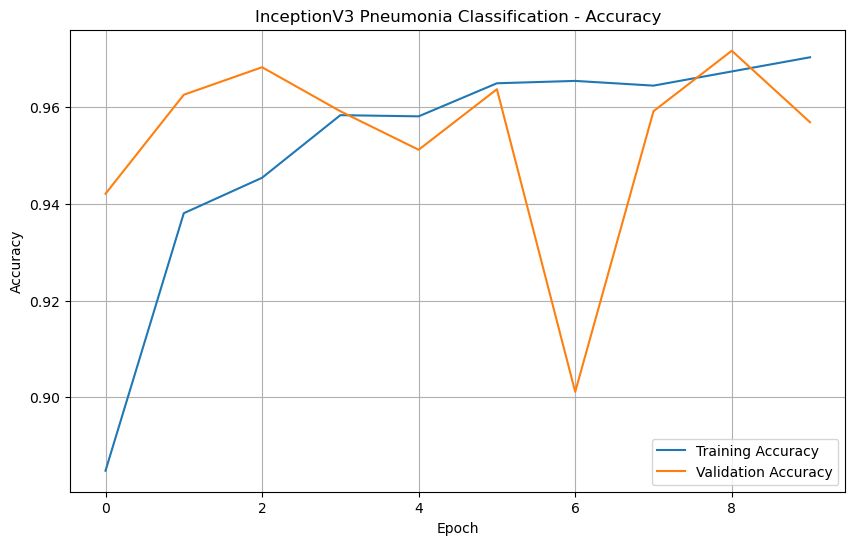

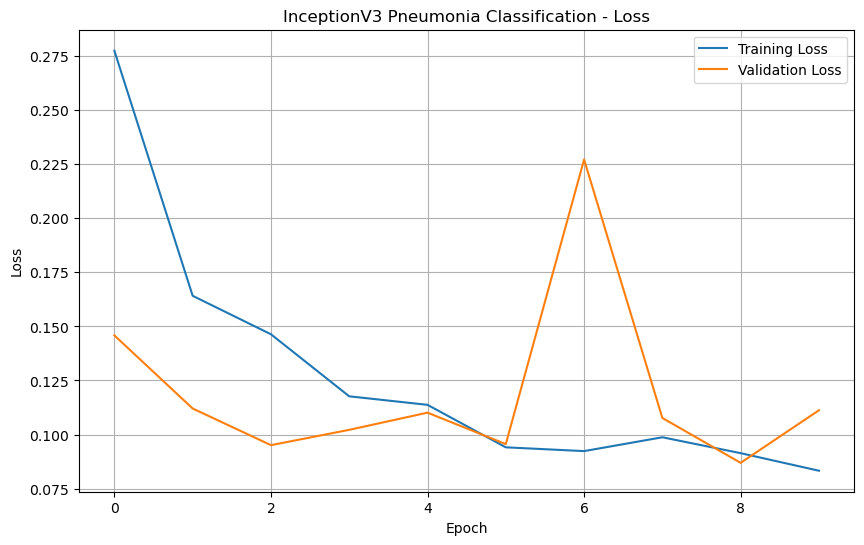


Final Training Accuracy: 97.02%
Final Validation Accuracy: 95.68%
Final Training Loss: 0.0833
Final Validation Loss: 0.1112

TESTING MODEL
28/28 ━━━━━━━━━━━━━━━━━━━━ 109s 4s/step - accuracy: 0.9662 - loss: 0.0836

Test Loss: 0.0994
Test Accuracy: 96.36%

GENERATING PREDICTIONS
28/28 ━━━━━━━━━━━━━━━━━━━━ 109s 4s/step

Total inference time: 111.2330 seconds
Average inference time per image: 0.126401 seconds
Images processed: 880

CONFUSION MATRIX
[[231   7]
 [ 25 617]]


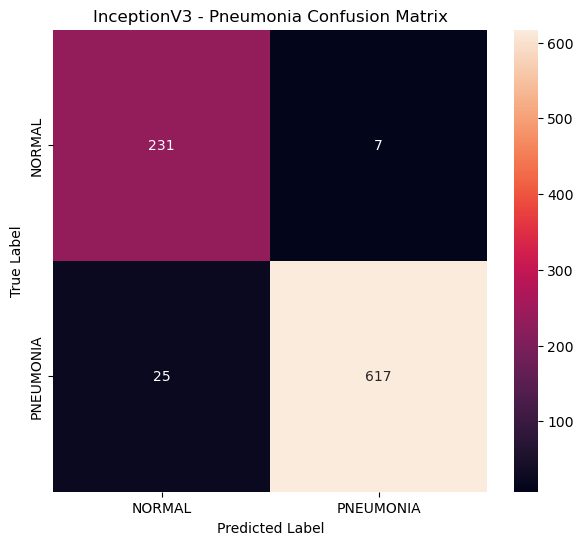


True Negative (TN): 231
False Positive (FP): 7
False Negative (FN): 25
True Positive (TP): 617

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL     0.9023    0.9706    0.9352       238
   PNEUMONIA     0.9888    0.9611    0.9747       642

    accuracy                         0.9636       880
   macro avg     0.9456    0.9658    0.9550       880
weighted avg     0.9654    0.9636    0.9640       880


ROC-AUC
ROC-AUC: 0.9949
ROC-AUC (%): 99.49%


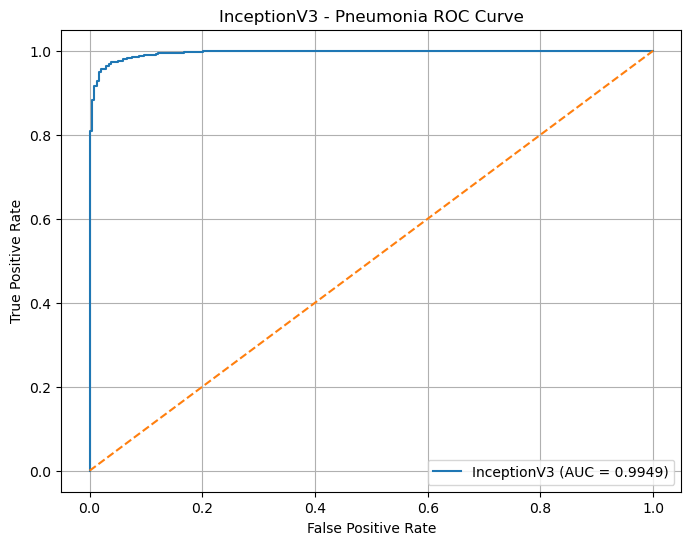


PRECISION-RECALL ANALYSIS
Average Precision (AP): 0.9981
Average Precision (%): 99.81%


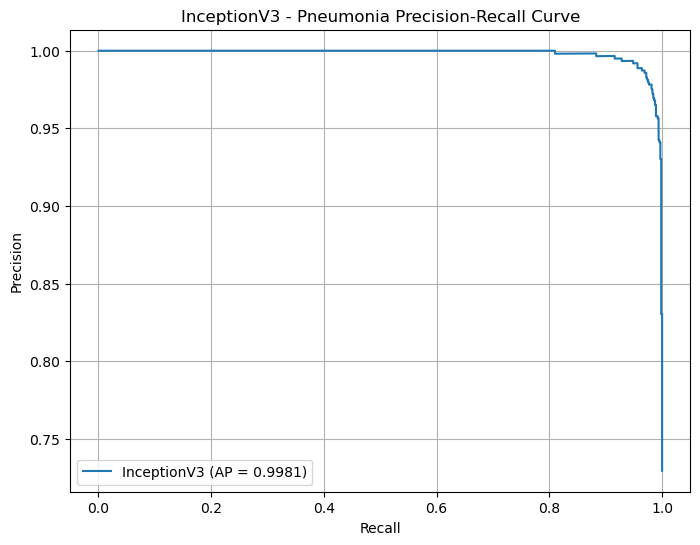


SENSITIVITY AND SPECIFICITY
Sensitivity: 0.9611
Sensitivity (%): 96.11%
Specificity: 0.9706
Specificity (%): 97.06%

MODEL SIZE
Model size: 129.51 MB


FINAL INCEPTIONV3 PNEUMONIA RESULTS
Training Accuracy       : 97.02%
Validation Accuracy     : 95.68%
Test Accuracy           : 96.36%
ROC-AUC                 : 99.49%
Average Precision       : 99.81%
Sensitivity             : 96.11%
Specificity             : 97.06%
Training Time           : 119.33 minutes
Avg. Inference/Image    : 0.126401 seconds
Model Size              : 129.51 MB
Model File              : inceptionv3_pneumonia_model.h5
EXPERIMENT COMPLETED SUCCESSFULLY


In [1]:
# ============================================================
# INCEPTIONV3 FOR PNEUMONIA CLASSIFICATION
# 10 EPOCHS - H5 MODEL
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.applications.inception_v3 import (
    InceptionV3,
    preprocess_input
)

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)


# Suppress non-critical warnings
warnings.filterwarnings("ignore")


print("=" * 70)
print("INCEPTIONV3 PNEUMONIA CLASSIFICATION")
print("=" * 70)

print("\nTensorFlow version:", tf.__version__)


# ============================================================
# 2. DATASET PATHS
# ============================================================

train_path = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\train"

val_path = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\val"

test_path = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\test"


# Pneumonia dataset classes
categories = ['NORMAL', 'PNEUMONIA']


# InceptionV3 requires 299 x 299 input
IMG_SIZE = (299, 299)

BATCH_SIZE = 32


# ============================================================
# 3. CHECK DATASET STRUCTURE
# ============================================================

print("\n" + "=" * 70)
print("CHECKING DATASET")
print("=" * 70)


print("\nTraining path:")
print(train_path)

print("\nValidation path:")
print(val_path)

print("\nTesting path:")
print(test_path)


# Check main folders
if not os.path.exists(train_path):
    raise FileNotFoundError(
        f"\nTraining folder not found:\n{train_path}"
    )

if not os.path.exists(val_path):
    raise FileNotFoundError(
        f"\nValidation folder not found:\n{val_path}"
    )

if not os.path.exists(test_path):
    raise FileNotFoundError(
        f"\nTesting folder not found:\n{test_path}"
    )


# Check class folders
for category in categories:

    train_folder = os.path.join(train_path, category)
    val_folder = os.path.join(val_path, category)
    test_folder = os.path.join(test_path, category)

    if not os.path.exists(train_folder):
        raise FileNotFoundError(
            f"\nTraining class folder not found:\n{train_folder}"
        )

    if not os.path.exists(val_folder):
        raise FileNotFoundError(
            f"\nValidation class folder not found:\n{val_folder}"
        )

    if not os.path.exists(test_folder):
        raise FileNotFoundError(
            f"\nTesting class folder not found:\n{test_folder}"
        )


print("\n✓ Dataset structure verified successfully!")


# ============================================================
# 4. COUNT IMAGES
# ============================================================

def count_images(folder):

    extensions = (
        '.jpg',
        '.jpeg',
        '.png',
        '.bmp',
        '.tif',
        '.tiff'
    )

    count = 0

    for root, dirs, files in os.walk(folder):

        for file in files:

            if file.lower().endswith(extensions):
                count += 1

    return count


print("\n" + "=" * 70)
print("DATASET STATISTICS")
print("=" * 70)


dataset_counts = {}


for split_name, split_path in [
    ("Training", train_path),
    ("Validation", val_path),
    ("Testing", test_path)
]:

    dataset_counts[split_name] = {}

    print(f"\n{split_name}:")

    total = 0

    for category in categories:

        folder = os.path.join(split_path, category)

        count = count_images(folder)

        dataset_counts[split_name][category] = count

        print(f"   {category}: {count}")

        total += count

    dataset_counts[split_name]["Total"] = total

    print(f"   Total: {total}")


# ============================================================
# 5. DATA AUGMENTATION
# ============================================================

print("\n" + "=" * 70)
print("CREATING IMAGE GENERATORS")
print("=" * 70)


train_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    rotation_range=15,

    zoom_range=0.15,

    horizontal_flip=True
)


val_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input
)


test_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input
)


# ============================================================
# 6. TRAINING GENERATOR
# ============================================================

train_gen = train_datagen.flow_from_directory(

    train_path,

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode='binary',

    classes=categories,

    shuffle=True
)


# ============================================================
# 7. VALIDATION GENERATOR
# ============================================================

val_gen = val_datagen.flow_from_directory(

    val_path,

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode='binary',

    classes=categories,

    shuffle=False
)


# ============================================================
# 8. TEST GENERATOR
# ============================================================

test_gen = test_datagen.flow_from_directory(

    test_path,

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode='binary',

    classes=categories,

    shuffle=False
)


print("\nClass indices:")
print(train_gen.class_indices)


print("\nTraining images:", train_gen.samples)

print("Validation images:", val_gen.samples)

print("Testing images:", test_gen.samples)


# ============================================================
# 9. BUILD INCEPTIONV3 BASE MODEL
# ============================================================

print("\n" + "=" * 70)
print("BUILDING INCEPTIONV3 MODEL")
print("=" * 70)


base_model = InceptionV3(

    weights='imagenet',

    include_top=False,

    input_shape=(299, 299, 3)
)


# Freeze all layers
for layer in base_model.layers:

    layer.trainable = False


# Unfreeze last 30 layers
for layer in base_model.layers[-30:]:

    layer.trainable = True


trainable_layers = sum(

    1
    for layer in base_model.layers
    if layer.trainable
)


total_layers = len(base_model.layers)


print("\nTotal base model layers:", total_layers)

print("Trainable base model layers:", trainable_layers)

print(
    "Frozen base model layers:",
    total_layers - trainable_layers
)


# ============================================================
# 10. BUILD CLASSIFICATION MODEL
# ============================================================

model = Sequential([

    base_model,

    GlobalAveragePooling2D(),

    Dense(
        256,
        activation='relu'
    ),

    Dropout(0.5),

    Dense(
        128,
        activation='relu'
    ),

    Dropout(0.3),

    Dense(
        1,
        activation='sigmoid'
    )
])


# ============================================================
# 11. COMPILE MODEL
# ============================================================

model.compile(

    optimizer=Adam(
        learning_rate=1e-4
    ),

    loss='binary_crossentropy',

    metrics=[
        'accuracy'
    ]
)


print("\nModel compiled successfully!")


# ============================================================
# 12. MODEL SUMMARY
# ============================================================

model.summary()


# ============================================================
# 13. TRAIN MODEL - 10 EPOCHS
# ============================================================

print("\n" + "=" * 70)
print("STARTING TRAINING")
print("=" * 70)


start_training_time = time.time()


history = model.fit(

    train_gen,

    validation_data=val_gen,

    epochs=10,

    verbose=1
)


end_training_time = time.time()


training_time = (
    end_training_time -
    start_training_time
)


print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)


print(
    f"\nTotal training time: "
    f"{training_time / 60:.2f} minutes"
)


# ============================================================
# 14. SAVE MODEL AS H5
# ============================================================

model_filename = "inceptionv3_pneumonia_model.h5"


model.save(model_filename)


print("\nModel saved successfully:")

print(os.path.abspath(model_filename))


# ============================================================
# 15. TRAINING CURVES
# ============================================================

print("\n" + "=" * 70)
print("TRAINING CURVES")
print("=" * 70)


# Accuracy curve
plt.figure(figsize=(10, 6))


plt.plot(

    history.history['accuracy'],

    label='Training Accuracy'
)


plt.plot(

    history.history['val_accuracy'],

    label='Validation Accuracy'
)


plt.title(
    'InceptionV3 Pneumonia Classification - Accuracy'
)

plt.xlabel('Epoch')

plt.ylabel('Accuracy')

plt.legend()

plt.grid(True)

plt.show()


# Loss curve
plt.figure(figsize=(10, 6))


plt.plot(

    history.history['loss'],

    label='Training Loss'
)


plt.plot(

    history.history['val_loss'],

    label='Validation Loss'
)


plt.title(
    'InceptionV3 Pneumonia Classification - Loss'
)

plt.xlabel('Epoch')

plt.ylabel('Loss')

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 16. FINAL TRAINING RESULTS
# ============================================================

final_train_accuracy = (
    history.history['accuracy'][-1]
)

final_val_accuracy = (
    history.history['val_accuracy'][-1]
)


final_train_loss = (
    history.history['loss'][-1]
)

final_val_loss = (
    history.history['val_loss'][-1]
)


print("\nFinal Training Accuracy:",
      f"{final_train_accuracy * 100:.2f}%")


print("Final Validation Accuracy:",
      f"{final_val_accuracy * 100:.2f}%")


print("Final Training Loss:",
      f"{final_train_loss:.4f}")


print("Final Validation Loss:",
      f"{final_val_loss:.4f}")


# ============================================================
# 17. TEST MODEL
# ============================================================

print("\n" + "=" * 70)
print("TESTING MODEL")
print("=" * 70)


test_loss, test_accuracy = model.evaluate(

    test_gen,

    verbose=1
)


print("\nTest Loss:",
      f"{test_loss:.4f}")


print(
    "Test Accuracy:",
    f"{test_accuracy * 100:.2f}%"
)


# ============================================================
# 18. GENERATE PREDICTIONS
# ============================================================

print("\n" + "=" * 70)
print("GENERATING PREDICTIONS")
print("=" * 70)


# Reset generator
test_gen.reset()


prediction_start_time = time.time()


y_probs = model.predict(

    test_gen,

    verbose=1
)


prediction_end_time = time.time()


# Convert probabilities to 1D array
y_probs = y_probs.ravel()


# Binary predictions
y_pred = (

    y_probs >= 0.5

).astype(int)


# True labels
y_true = test_gen.classes


# ============================================================
# 19. INFERENCE TIME
# ============================================================

total_inference_time = (

    prediction_end_time -
    prediction_start_time
)


num_test_images = len(y_true)


average_inference_time = (

    total_inference_time /
    num_test_images
)


print(
    "\nTotal inference time:",
    f"{total_inference_time:.4f} seconds"
)


print(
    "Average inference time per image:",
    f"{average_inference_time:.6f} seconds"
)


print(
    "Images processed:",
    num_test_images
)


# ============================================================
# 20. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(

    y_true,

    y_pred
)


print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)


print(cm)


plt.figure(figsize=(7, 6))


sns.heatmap(

    cm,

    annot=True,

    fmt='d',

    xticklabels=categories,

    yticklabels=categories
)


plt.title(
    'InceptionV3 - Pneumonia Confusion Matrix'
)

plt.xlabel('Predicted Label')

plt.ylabel('True Label')

plt.show()


# ============================================================
# 21. EXTRACT TP, TN, FP, FN
# ============================================================

if cm.shape == (2, 2):

    tn, fp, fn, tp = cm.ravel()

else:

    tn = fp = fn = tp = 0


print("\nTrue Negative (TN):", tn)

print("False Positive (FP):", fp)

print("False Negative (FN):", fn)

print("True Positive (TP):", tp)


# ============================================================
# 22. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)


report = classification_report(

    y_true,

    y_pred,

    target_names=categories,

    digits=4
)


print(report)


# ============================================================
# 23. ROC CURVE AND ROC-AUC
# ============================================================

fpr, tpr, thresholds = roc_curve(

    y_true,

    y_probs
)


roc_auc = auc(

    fpr,

    tpr
)


print("\n" + "=" * 70)
print("ROC-AUC")
print("=" * 70)


print(

    "ROC-AUC:",

    f"{roc_auc:.4f}"
)


print(

    "ROC-AUC (%):",

    f"{roc_auc * 100:.2f}%"
)


plt.figure(figsize=(8, 6))


plt.plot(

    fpr,

    tpr,

    label=f'InceptionV3 (AUC = {roc_auc:.4f})'
)


plt.plot(

    [0, 1],

    [0, 1],

    linestyle='--'
)


plt.xlabel('False Positive Rate')

plt.ylabel('True Positive Rate')

plt.title(
    'InceptionV3 - Pneumonia ROC Curve'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 24. PRECISION-RECALL CURVE
# ============================================================

precision, recall, pr_thresholds = (

    precision_recall_curve(

        y_true,

        y_probs

    )
)


average_precision = (

    average_precision_score(

        y_true,

        y_probs

    )
)


print("\n" + "=" * 70)
print("PRECISION-RECALL ANALYSIS")
print("=" * 70)


print(

    "Average Precision (AP):",

    f"{average_precision:.4f}"
)


print(

    "Average Precision (%):",

    f"{average_precision * 100:.2f}%"
)


plt.figure(figsize=(8, 6))


plt.plot(

    recall,

    precision,

    label=f'InceptionV3 (AP = {average_precision:.4f})'
)


plt.xlabel('Recall')

plt.ylabel('Precision')

plt.title(
    'InceptionV3 - Pneumonia Precision-Recall Curve'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 25. SENSITIVITY AND SPECIFICITY
# ============================================================

if (tp + fn) > 0:

    sensitivity = (

        tp /
        (tp + fn)

    )

else:

    sensitivity = 0


if (tn + fp) > 0:

    specificity = (

        tn /
        (tn + fp)

    )

else:

    specificity = 0


print("\n" + "=" * 70)
print("SENSITIVITY AND SPECIFICITY")
print("=" * 70)


print(

    "Sensitivity:",

    f"{sensitivity:.4f}"
)


print(

    "Sensitivity (%):",

    f"{sensitivity * 100:.2f}%"
)


print(

    "Specificity:",

    f"{specificity:.4f}"
)


print(

    "Specificity (%):",

    f"{specificity * 100:.2f}%"
)


# ============================================================
# 26. MODEL SIZE
# ============================================================

model_size_bytes = os.path.getsize(

    model_filename
)


model_size_mb = (

    model_size_bytes /
    (1024 ** 2)

)


print("\n" + "=" * 70)
print("MODEL SIZE")
print("=" * 70)


print(

    "Model size:",

    f"{model_size_mb:.2f} MB"
)


# ============================================================
# 27. FINAL SUMMARY
# ============================================================

print("\n")

print("=" * 70)

print("FINAL INCEPTIONV3 PNEUMONIA RESULTS")

print("=" * 70)


print(

    f"Training Accuracy       : "
    f"{final_train_accuracy * 100:.2f}%"
)


print(

    f"Validation Accuracy     : "
    f"{final_val_accuracy * 100:.2f}%"
)


print(

    f"Test Accuracy           : "
    f"{test_accuracy * 100:.2f}%"
)


print(

    f"ROC-AUC                 : "
    f"{roc_auc * 100:.2f}%"
)


print(

    f"Average Precision       : "
    f"{average_precision * 100:.2f}%"
)


print(

    f"Sensitivity             : "
    f"{sensitivity * 100:.2f}%"
)


print(

    f"Specificity             : "
    f"{specificity * 100:.2f}%"
)


print(

    f"Training Time           : "
    f"{training_time / 60:.2f} minutes"
)


print(

    f"Avg. Inference/Image    : "
    f"{average_inference_time:.6f} seconds"
)


print(

    f"Model Size              : "
    f"{model_size_mb:.2f} MB"
)


print(

    f"Model File              : "
    f"{model_filename}"
)


print("=" * 70)

print("EXPERIMENT COMPLETED SUCCESSFULLY")

print("=" * 70)